# Project 2 — Data Cleaning and Preprocessing

**Oasis Infobyte | Data Analytics Track**  
**Student:** Piyush Ramesh Bhor  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

## Objective

Demonstrate a repeatable data-cleaning workflow using a Titanic passenger dataset. The work includes a data-quality report, missing-value treatment with reasons, duplicate removal, formatting standardisation, outlier detection, data-type correction, a before/after comparison, and export of the cleaned CSV.

## Important methodology note

The notebook starts with a public Titanic dataset, then creates a **separate, reproducible messy practice copy** by introducing controlled examples of inconsistent text, malformed numeric values, missing values, an extreme fare and duplicate rows. This allows the cleaning steps to be demonstrated transparently. The original dataset is retained unchanged.

All reported counts and model-free descriptive results are generated by executing the notebook. Do not manually invent or change the outputs.

# Project 2 — Data Cleaning and Preprocessing

**Oasis Infobyte | Data Analytics Track**  
**Student:** Piyush Ramesh Bhor  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

## Objective

Demonstrate a repeatable data-cleaning workflow using a Titanic passenger dataset. The work includes a data-quality report, missing-value treatment with reasons, duplicate removal, formatting standardisation, outlier detection, data-type correction, a before/after comparison, and export of the cleaned CSV.

## Important methodology note

The notebook starts with a public Titanic dataset, then creates a **separate, reproducible messy practice copy** by introducing controlled examples of inconsistent text, malformed numeric values, missing values, an extreme fare and duplicate rows. This allows the cleaning steps to be demonstrated transparently. The original dataset is retained unchanged.

All reported counts and model-free descriptive results are generated by executing the notebook. Do not manually invent or change the outputs.

## 1. Import libraries and configure output folder

This section imports the libraries used throughout the project and creates an `outputs` folder for cleaned data, reports and charts.

In [ ]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)
print("Libraries imported and output folder ready:", OUTPUT_DIR)

Libraries imported and output folder ready: outputs


## 2. Load the original dataset

The notebook first tries a public CSV source. If the URL is unavailable, upload a Titanic CSV file when prompted. The original data is not modified.

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/sitmbadept/sitmbadept.github.io/main/BDTM/R/titanic.csv"

try:
    original = pd.read_csv(DATA_URL)
    print("Loaded the Titanic dataset from the public CSV source.")
except Exception as download_error:
    print("Automatic download failed:", download_error)
    print("Please upload a Titanic CSV file (for example, train.csv).")
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise ValueError("No file was uploaded.")
        uploaded_name = next(iter(uploaded))
        original = pd.read_csv(uploaded_name)
    except ImportError:
        uploaded_name = input("Enter the path to your Titanic CSV file: ").strip()
        original = pd.read_csv(uploaded_name)

# Standardise column names for consistent processing.
original.columns = [str(c).strip().lower().replace(" ", "_") for c in original.columns]

# Some Titanic versions use slightly different column names.
column_aliases = {
    "passenger_id": "passengerid",
    "class": "pclass",
    "embark_town": "embarked",
    "deck": "cabin"
}
for old_name, new_name in column_aliases.items():
    if old_name in original.columns and new_name not in original.columns:
        original = original.rename(columns={old_name: new_name})

# Ensure the dataset has a usable passenger identifier.
if "passengerid" not in original.columns:
    original.insert(0, "passengerid", np.arange(1, len(original) + 1))

required = ["pclass", "sex", "age", "fare", "embarked"]
missing_required = [c for c in required if c not in original.columns]
if missing_required:
    raise ValueError(f"The uploaded dataset is missing required columns: {missing_required}. Please use a standard Titanic CSV.")

print("Original dataset shape:", original.shape)
print("Columns:", original.columns.tolist())
display(original.head())

Loaded the Titanic dataset from the public CSV source.
Original dataset shape: (891, 12)
Columns: ['passengerid', 'survived', 'pclass', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket', 'fare', 'cabin', 'embarked']


,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Create a reproducible messy practice copy

To demonstrate cleaning, controlled issues are added to a copy: inconsistent category labels, text inside numeric columns, missing values, one extreme fare and duplicate records. The random seed makes the process reproducible.

In [ ]:
messy = original.copy(deep=True)

# A. Inconsistent formatting in categorical columns.
if "sex" in messy.columns:
    messy["sex"] = messy["sex"].astype("object")
    idx = messy.index[messy["sex"].notna()].to_numpy()
    chosen = rng.choice(idx, size=min(12, len(idx)), replace=False)
    variants = [" Male ", "FEMALE", "female ", "MALE", "m", "F"]
    for row_idx, value in zip(chosen, (variants * 3)[:len(chosen)]):
        messy.loc[row_idx, "sex"] = value

if "embarked" in messy.columns:
    messy["embarked"] = messy["embarked"].astype("object")
    idx = messy.index[messy["embarked"].notna()].to_numpy()
    chosen = rng.choice(idx, size=min(9, len(idx)), replace=False)
    variants = [" s ", "c", "Q ", "S", "southampton"]
    for row_idx, value in zip(chosen, (variants * 2)[:len(chosen)]):
        messy.loc[row_idx, "embarked"] = value

# B. Malformed numeric values and additional missing values.
if "age" in messy.columns:
    messy["age"] = messy["age"].astype("object")
    idx = messy.index[messy["age"].notna()].to_numpy()
    chosen = rng.choice(idx, size=min(8, len(idx)), replace=False)
    variants = ["unknown", "42 years", "N/A", " 31 "] * 2
    for row_idx, value in zip(chosen, variants[:len(chosen)]):
        messy.loc[row_idx, "age"] = value
    missing_idx = messy.sample(min(10, len(messy)), random_state=7).index
    messy.loc[missing_idx, "age"] = np.nan

if "fare" in messy.columns:
    messy["fare"] = messy["fare"].astype("object")
    idx = messy.index[messy["fare"].notna()].to_numpy()
    chosen = rng.choice(idx, size=min(6, len(idx)), replace=False)
    for row_idx in chosen[:3]:
        messy.loc[row_idx, "fare"] = "$" + str(messy.loc[row_idx, "fare"])
    for row_idx in chosen[3:]:
        value = str(messy.loc[row_idx, "fare"])
        messy.loc[row_idx, "fare"] = value.replace(".", ",")
    missing_idx = messy.sample(min(5, len(messy)), random_state=12).index
    messy.loc[missing_idx, "fare"] = np.nan
    numeric_fare = pd.to_numeric(
        messy["fare"].astype("string").str.replace("$", "", regex=False).str.replace(",", ".", regex=False),
        errors="coerce"
    )
    if numeric_fare.notna().any():
        messy.loc[numeric_fare.idxmax(), "fare"] = float(numeric_fare.max()) * 20

# C. Add exact duplicate rows so duplicate detection can be demonstrated.
extra_duplicates = messy.sample(min(6, len(messy)), random_state=21)
messy = pd.concat([messy, extra_duplicates], ignore_index=True)

messy.to_csv(f"{OUTPUT_DIR}/titanic_messy_practice.csv", index=False)
print("Original rows:", len(original))
print("Messy practice copy shape:", messy.shape)
display(messy.head())

Original rows: 891
Messy practice copy shape: (897, 12)


,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.05,NaN,S


## 4. Data-quality report before cleaning

The report checks missing values, duplicates, data types, formatting issues and invalid numeric ranges. For this exercise, age values outside 0–100, negative fares/counts, invalid passenger classes and invalid survival flags are treated as range anomalies.

In [ ]:
def parse_mixed_number(value):
    """Parse numbers that may contain currency symbols or comma decimal separators."""
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    text = re.sub(r"[^0-9,.-]", "", text)
    if not text:
        return np.nan
    if "," in text and "." in text:
        # If both separators exist, assume commas are thousands separators.
        text = text.replace(",", "")
    elif "," in text:
        # If only a comma exists, treat it as a decimal separator.
        text = text.replace(",", ".")
    try:
        return float(text)
    except ValueError:
        return np.nan

def count_range_anomalies(data):
    checks = {
        "age_outside_0_100": ("age", lambda s: (s < 0) | (s > 100)),
        "negative_fare": ("fare", lambda s: s < 0),
        "invalid_pclass": ("pclass", lambda s: ~s.isin([1, 2, 3])),
        "negative_sibsp": ("sibsp", lambda s: s < 0),
        "negative_parch": ("parch", lambda s: s < 0),
        "invalid_survived": ("survived", lambda s: ~s.isin([0, 1]))
    }
    details = {}
    for label, (col, condition) in checks.items():
        if col in data.columns:
            numeric = data[col].map(parse_mixed_number)
            details[label] = int(condition(numeric).fillna(False).sum())
    return details

def make_quality_report(data, stage):
    report = pd.DataFrame({
        "column": data.columns,
        "data_type": [str(dtype) for dtype in data.dtypes],
        "missing_values": data.isna().sum().values,
        "missing_percent": (data.isna().mean().values * 100).round(2),
        "unique_values": data.nunique(dropna=True).values
    })
    anomaly_details = count_range_anomalies(data)
    print(f"{stage}: {len(data):,} rows × {data.shape[1]} columns")
    print("Exact duplicate rows:", int(data.duplicated().sum()))
    print("Total missing cells:", int(data.isna().sum().sum()))
    print("Range anomaly counts:", anomaly_details)
    display(report)
    return report, anomaly_details

before_report, anomalies_before = make_quality_report(messy, "BEFORE CLEANING")
before_report.to_csv(f"{OUTPUT_DIR}/quality_report_before.csv", index=False)

BEFORE CLEANING: 897 rows × 12 columns
Exact duplicate rows: 6
Total missing cells: 888
Range anomaly counts: {'age_outside_0_100': 0, 'negative_fare': 0, 'invalid_pclass': 0, 'negative_sibsp': 0, 'negative_parch': 0, 'invalid_survived': 0}


,column,data_type,missing_values,missing_percent,unique_values
0,passengerid,int64,0,0.00,891
1,survived,int64,0,0.00,2
2,pclass,int64,0,0.00,3
3,name,object,0,0.00,891
4,sex,object,0,0.00,8
5,age,object,188,20.96,92
6,sibsp,int64,0,0.00,7
7,parch,int64,0,0.00,7
8,ticket,object,0,0.00,681
9,fare,object,5,0.56,254


## 5. Visualise missing values before cleaning

This chart shows which columns contain missing values before the cleaning process.

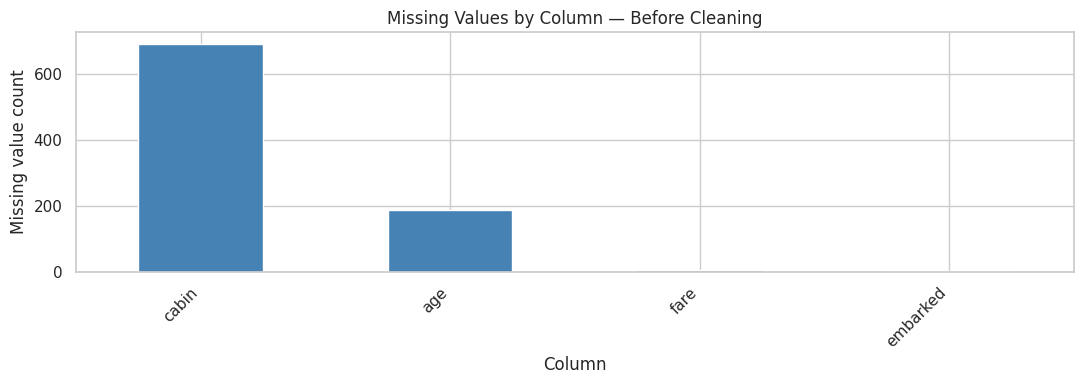

In [ ]:
missing_before = messy.isna().sum().sort_values(ascending=False)
plt.figure(figsize=(11, 4))
missing_before[missing_before > 0].plot(kind="bar", color="steelblue")
plt.title("Missing Values by Column — Before Cleaning")
plt.xlabel("Column")
plt.ylabel("Missing value count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/missing_values_before.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Remove duplicates and standardise values

**Decisions:** exact duplicate rows are removed; sex labels are standardised to `Male`/`Female`; embarkation codes are standardised to uppercase; numeric text is converted to numeric values; invalid negative ages/fares and impossible ages are converted to missing values so they can be handled explicitly.

In [ ]:
clean = messy.copy(deep=True)
rows_before_deduplication = len(clean)
clean = clean.drop_duplicates().copy()
duplicates_removed = rows_before_deduplication - len(clean)

# Standardise the sex field.
if "sex" in clean.columns:
    sex = clean["sex"].astype("string").str.strip().str.lower()
    sex = sex.replace({"m": "male", "f": "female", "woman": "female", "man": "male"})
    clean["sex"] = sex.map({"male": "Male", "female": "Female"}).astype("string")

# Standardise embarkation ports to S, C or Q.
if "embarked" in clean.columns:
    embarked = clean["embarked"].astype("string").str.strip().str.lower()
    embarked = embarked.replace({
        "southampton": "s", "cherbourg": "c", "queenstown": "q",
        "": pd.NA, "nan": pd.NA, "none": pd.NA
    })
    clean["embarked"] = embarked.str.upper()
    clean.loc[~clean["embarked"].isin(["S", "C", "Q"]), "embarked"] = pd.NA

# Parse age and fare robustly.
if "age" in clean.columns:
    age_text = clean["age"].astype("string").str.extract(r"(-?\d+(?:\.\d+)?)", expand=False)
    clean["age"] = pd.to_numeric(age_text, errors="coerce")
    clean.loc[(clean["age"] < 0) | (clean["age"] > 100), "age"] = np.nan

if "fare" in clean.columns:
    clean["fare"] = clean["fare"].map(parse_mixed_number)
    clean.loc[clean["fare"] < 0, "fare"] = np.nan

# Convert count/class fields to numeric before checking their validity.
for col in ["survived", "pclass", "sibsp", "parch"]:
    if col in clean.columns:
        clean[col] = pd.to_numeric(clean[col], errors="coerce")

if "pclass" in clean.columns:
    clean.loc[~clean["pclass"].isin([1, 2, 3]), "pclass"] = np.nan
if "survived" in clean.columns:
    clean.loc[~clean["survived"].isin([0, 1]), "survived"] = np.nan
for col in ["sibsp", "parch"]:
    if col in clean.columns:
        clean.loc[clean[col] < 0, col] = np.nan

print("Exact duplicate rows removed:", duplicates_removed)
print("Rows after duplicate removal:", len(clean))
display(clean.head())

Exact duplicate rows removed: 6
Rows after duplicate removal: 891


,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0.0,3.0,"Braund, Mr. Owen Harris",Male,22.0,1.0,0.0,A/5 21171,7.2500,NaN,S
1,2,1.0,1.0,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Female,38.0,1.0,0.0,PC 17599,71.2833,C85,C
2,3,1.0,3.0,"Heikkinen, Miss. Laina",Female,26.0,0.0,0.0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1.0,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Female,35.0,1.0,0.0,113803,53.1000,C123,S
4,5,0.0,3.0,"Allen, Mr. William Henry",Male,35.0,0.0,0.0,373450,8.0500,NaN,S


## 7. Handle missing values with documented reasons

| Column | Treatment | Reason |
|---|---|---|
| Age | Median within passenger class; global median fallback | Median is less affected by extreme values; class grouping keeps broad passenger-class differences. |
| Fare | Median within passenger class; global median fallback | Fares differ by passenger class, so class-specific medians are more appropriate than one overall value. |
| Embarked | Mode (most frequent port) | A small number of missing categorical entries are replaced with the most common category. |
| Cabin | `Unknown` | Cabin is missing for many passengers; assigning a guessed cabin would be misleading. |
| Other remaining numeric columns | Median | Preserves rows and is robust to skew. |
| Other remaining categorical columns | `Unknown` | Avoids inventing a category or deleting potentially useful rows. |

In [ ]:
# Age: class-specific median, then global median.
if "age" in clean.columns:
    if "pclass" in clean.columns:
        clean["age"] = clean.groupby("pclass")["age"].transform(lambda s: s.fillna(s.median()))
    clean["age"] = clean["age"].fillna(clean["age"].median())

# Fare: class-specific median, then global median.
if "fare" in clean.columns:
    if "pclass" in clean.columns:
        clean["fare"] = clean.groupby("pclass")["fare"].transform(lambda s: s.fillna(s.median()))
    clean["fare"] = clean["fare"].fillna(clean["fare"].median())

# Embarked: mode, if the column has at least one known value.
if "embarked" in clean.columns and clean["embarked"].notna().any():
    clean["embarked"] = clean["embarked"].fillna(clean["embarked"].mode().iloc[0])

# Cabin: missing means no recorded cabin. Do not guess a cabin value.
if "cabin" in clean.columns:
    clean["cabin"] = clean["cabin"].astype("string").fillna("Unknown")

# Handle any other remaining missing fields explicitly.
for col in clean.columns:
    if clean[col].isna().any():
        if pd.api.types.is_numeric_dtype(clean[col]):
            median_value = clean[col].median()
            if pd.isna(median_value):
                # Entirely empty numeric columns are marked with -1 rather than silently left missing.
                clean[col] = clean[col].fillna(-1)
            else:
                clean[col] = clean[col].fillna(median_value)
        else:
            clean[col] = clean[col].astype("string").fillna("Unknown")

print("Remaining missing cells:", int(clean.isna().sum().sum()))
display(clean.isna().sum().to_frame("remaining_missing"))

Remaining missing cells: 0


,remaining_missing
passengerid,0
survived,0
pclass,0
name,0
sex,0
age,0
sibsp,0
parch,0
ticket,0
fare,0


## 8. Detect outliers using the IQR method

The Interquartile Range (IQR) method uses Q1 − 1.5 × IQR and Q3 + 1.5 × IQR as lower and upper screening limits. In this exercise, valid age extremes are retained because young and elderly passenger ages can be legitimate. Extreme fare values are capped at the upper IQR limit to reduce the effect of the deliberately inserted extreme value; the row is retained.

In [ ]:
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

outlier_rows = []
for col in ["age", "fare"]:
    if col in clean.columns and clean[col].notna().any():
        lower, upper = iqr_bounds(clean[col].dropna())
        outlier_mask = (clean[col] < lower) | (clean[col] > upper)
        outlier_rows.append({
            "column": col, "lower_IQR_bound": lower, "upper_IQR_bound": upper,
            "outlier_count": int(outlier_mask.sum()), "treatment": "Retained" if col == "age" else "Upper-tail capped"
        })
        if col == "fare":
            clean[col] = clean[col].clip(lower=max(0, lower), upper=upper)

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)
outlier_summary.to_csv(f"{OUTPUT_DIR}/outlier_summary.csv", index=False)

,column,lower_IQR_bound,upper_IQR_bound,outlier_count,treatment
0,age,0.62500,57.62500,34,Retained
1,fare,-26.93025,65.97815,116,Upper-tail capped


## 9. Correct data types and create the before/after report

Passenger IDs are stored as strings because they are identifiers, not quantities. Passenger class, survival flag and family-count columns are nullable integers. Age and fare are numeric. Text columns use pandas string dtype.

In [ ]:
# Apply stable, documented data types.
if "passengerid" in clean.columns:
    clean["passengerid"] = clean["passengerid"].astype("string")
for col in ["survived", "pclass", "sibsp", "parch"]:
    if col in clean.columns:
        clean[col] = pd.to_numeric(clean[col], errors="coerce").round().astype("Int64")
for col in ["age", "fare"]:
    if col in clean.columns:
        clean[col] = pd.to_numeric(clean[col], errors="coerce").astype(float)
for col in clean.select_dtypes(include=["object"]).columns:
    clean[col] = clean[col].astype("string")

# Expected data types used to calculate dtype accuracy.
expected_types = {}
for col in ["passengerid", "name", "sex", "ticket", "cabin", "embarked"]:
    if col in clean.columns:
        expected_types[col] = "string"
for col in ["survived", "pclass", "sibsp", "parch"]:
    if col in clean.columns:
        expected_types[col] = "integer"
for col in ["age", "fare"]:
    if col in clean.columns:
        expected_types[col] = "numeric"

def dtype_accuracy(data):
    checks = []
    for col, expected in expected_types.items():
        dtype = data[col].dtype
        if expected == "string":
            valid = pd.api.types.is_string_dtype(dtype) or pd.api.types.is_object_dtype(dtype)
        elif expected == "integer":
            valid = pd.api.types.is_integer_dtype(dtype)
        else:
            valid = pd.api.types.is_numeric_dtype(dtype)
        checks.append((col, expected, str(dtype), bool(valid)))
    detail = pd.DataFrame(checks, columns=["column", "expected_type", "actual_type", "type_correct"])
    accuracy = 100 * detail["type_correct"].mean() if len(detail) else 100.0
    return float(accuracy), detail

before_dtype_accuracy, before_dtype_detail = dtype_accuracy(messy)
after_dtype_accuracy, after_dtype_detail = dtype_accuracy(clean)
after_report, anomalies_after = make_quality_report(clean, "AFTER CLEANING")

summary = pd.DataFrame([
    {"metric": "row_count", "before": len(messy), "after": len(clean)},
    {"metric": "duplicate_rows", "before": int(messy.duplicated().sum()), "after": int(clean.duplicated().sum())},
    {"metric": "missing_cells", "before": int(messy.isna().sum().sum()), "after": int(clean.isna().sum().sum())},
    {"metric": "range_anomalies", "before": int(sum(anomalies_before.values())), "after": int(sum(anomalies_after.values()))},
    {"metric": "dtype_accuracy_percent", "before": round(before_dtype_accuracy, 2), "after": round(after_dtype_accuracy, 2)}
])
print("BEFORE vs AFTER SUMMARY")
display(summary)
print("Final dtype verification")
display(after_dtype_detail)
summary.to_csv(f"{OUTPUT_DIR}/before_after_summary.csv", index=False)
after_dtype_detail.to_csv(f"{OUTPUT_DIR}/dtype_verification.csv", index=False)
after_report.to_csv(f"{OUTPUT_DIR}/quality_report_after.csv", index=False)

AFTER CLEANING: 891 rows × 12 columns
Exact duplicate rows: 0
Total missing cells: 0
Range anomaly counts: {'age_outside_0_100': 0, 'negative_fare': 0, 'invalid_pclass': 0, 'negative_sibsp': 0, 'negative_parch': 0, 'invalid_survived': 0}


,column,data_type,missing_values,missing_percent,unique_values
0,passengerid,string,0,0.0,891
1,survived,Int64,0,0.0,2
2,pclass,Int64,0,0.0,3
3,name,string,0,0.0,891
4,sex,string,0,0.0,2
5,age,float64,0,0.0,88
6,sibsp,Int64,0,0.0,7
7,parch,Int64,0,0.0,7
8,ticket,string,0,0.0,681
9,fare,float64,0,0.0,203


BEFORE vs AFTER SUMMARY


,metric,before,after
0,row_count,897.0,891.0
1,duplicate_rows,6.0,0.0
2,missing_cells,888.0,0.0
3,range_anomalies,0.0,0.0
4,dtype_accuracy_percent,75.0,100.0


Final dtype verification


,column,expected_type,actual_type,type_correct
0,passengerid,string,string,True
1,name,string,string,True
2,sex,string,string,True
3,ticket,string,string,True
4,cabin,string,string,True
5,embarked,string,string,True
6,survived,integer,Int64,True
7,pclass,integer,Int64,True
8,sibsp,integer,Int64,True
9,parch,integer,Int64,True


## 10. Compare selected distributions before and after cleaning

The charts below compare age and fare distributions before and after cleaning. The pre-cleaning columns are converted to numeric for plotting, so malformed text values are excluded from the before-cleaning histograms.

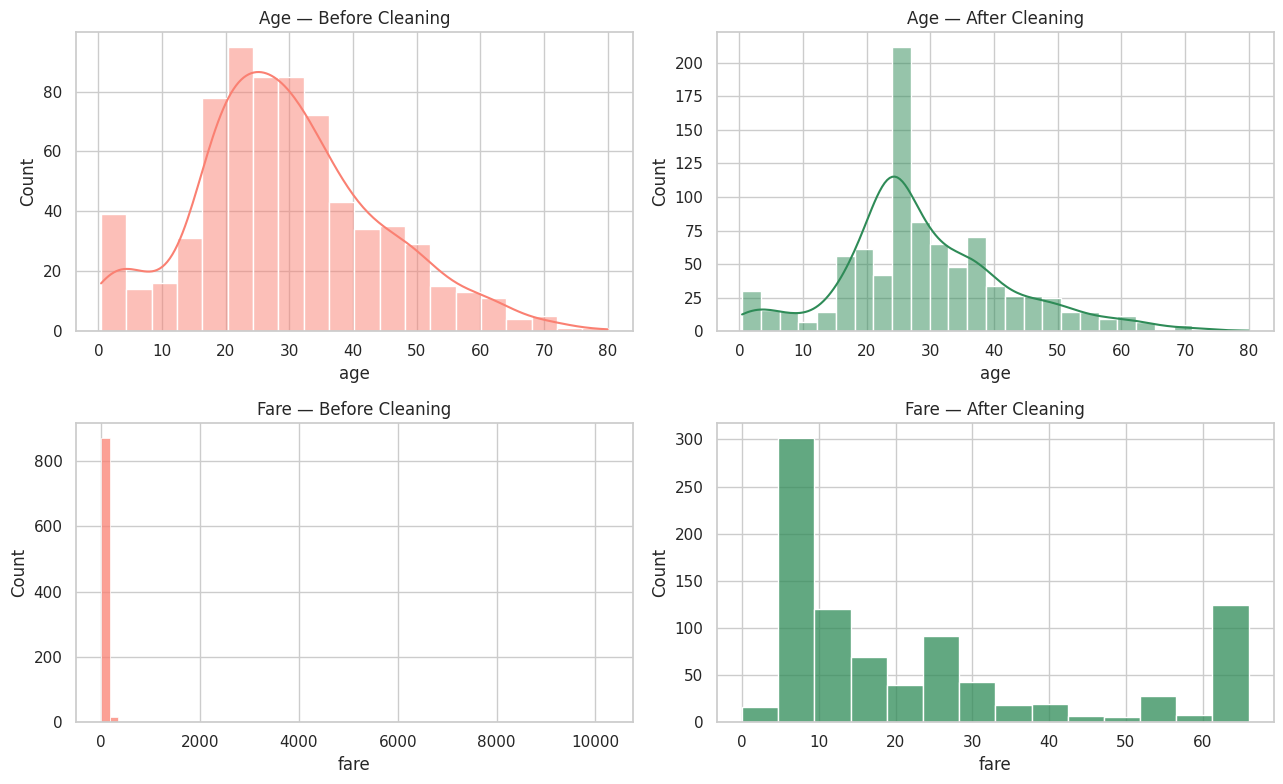

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

if "age" in messy.columns:
    age_before = pd.to_numeric(messy["age"].astype("string").str.extract(r"(-?\d+(?:\.\d+)?)", expand=False), errors="coerce")
    sns.histplot(age_before.dropna(), kde=True, ax=axes[0, 0], color="salmon")
    axes[0, 0].set_title("Age — Before Cleaning")
    sns.histplot(clean["age"].dropna(), kde=True, ax=axes[0, 1], color="seagreen")
    axes[0, 1].set_title("Age — After Cleaning")

if "fare" in messy.columns:
    fare_before = messy["fare"].map(parse_mixed_number)
    sns.histplot(fare_before.dropna(), kde=False, ax=axes[1, 0], color="salmon")
    axes[1, 0].set_title("Fare — Before Cleaning")
    sns.histplot(clean["fare"].dropna(), kde=False, ax=axes[1, 1], color="seagreen")
    axes[1, 1].set_title("Fare — After Cleaning")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/before_after_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

## 11. Export cleaned dataset and quality reports

The cleaned CSV and supporting reports are saved in the `outputs` folder. A ZIP file is also created so the deliverables can be downloaded together from Google Colab.

In [ ]:
clean.to_csv(f"{OUTPUT_DIR}/titanic_cleaned.csv", index=False)
before_report.to_csv(f"{OUTPUT_DIR}/quality_report_before.csv", index=False)
summary.to_csv(f"{OUTPUT_DIR}/before_after_summary.csv", index=False)
after_dtype_detail.to_csv(f"{OUTPUT_DIR}/dtype_verification.csv", index=False)
after_report.to_csv(f"{OUTPUT_DIR}/quality_report_after.csv", index=False)

import shutil
shutil.make_archive("Project_2_Data_Cleaning_Outputs", "zip", OUTPUT_DIR)
print("Saved files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", filename)
print("\nCreated: Project_2_Data_Cleaning_Outputs.zip")
print("Cleaned dataset shape:", clean.shape)
print("Missing cells after cleaning:", int(clean.isna().sum().sum()))
print("Duplicate rows after cleaning:", int(clean.duplicated().sum()))

Saved files:
 - before_after_distributions.png
 - before_after_summary.csv
 - dtype_verification.csv
 - missing_values_before.png
 - outlier_summary.csv
 - quality_report_after.csv
 - quality_report_before.csv
 - titanic_cleaned.csv
 - titanic_messy_practice.csv

Created: Project_2_Data_Cleaning_Outputs.zip
Cleaned dataset shape: (891, 12)
Missing cells after cleaning: 0
Duplicate rows after cleaning: 0


## 12. Findings and conclusion

### Summary of work performed

This project demonstrates a repeatable data-cleaning workflow using a deliberately modified Titanic passenger dataset. The original dataset contained **891 rows and 12 columns**. For practice, six exact duplicate rows and additional data-quality issues were introduced, producing a pre-cleaning dataset of **897 rows × 12 columns**.

The cleaning workflow:
1. Inspected the dataset structure, data types, missing values, unique values, duplicate rows and selected numeric range rules.
2. Standardised inconsistent `sex` and `embarked` labels, and parsed mixed text/numeric values in `age` and `fare`.
3. Removed **6 exact duplicate rows**, returning the dataset to **891 rows**.
4. Imputed missing `age` and `fare` values using passenger-class medians (with a global-median fallback), filled missing `embarked` values with the mode, and labelled unrecorded `cabin` values as `Unknown`.
5. Detected outliers with the IQR method. The notebook flagged **34 age observations** and **116 fare observations**. Age observations were retained; the upper tail of `fare` was capped at the IQR upper bound of **65.97815**. No rows were removed by this outlier treatment.
6. Corrected identifier, categorical, integer and numeric data types.
7. Exported the cleaned dataset and supporting quality reports, including before/after summaries and distribution charts.

### Before-and-after data-quality results

| Measure | Before cleaning | After cleaning |
|---|---:|---:|
| Rows | 897 | 891 |
| Columns | 12 | 12 |
| Exact duplicate rows | 6 | 0 |
| Missing cells | 888 | 0 |
| Data-type accuracy | 75% | 100% |
| Checked range anomalies | 0 | 0 |

The missing values before cleaning were concentrated in `cabin` (693), `age` (188), `fare` (5) and `embarked` (2). After the documented imputation and labelling rules, the cleaned dataset contains no missing cells. The reported range-anomaly count refers only to the explicit checks in this notebook (for example, negative fares, ages outside 0–100 and invalid class/survival codes); it does not replace the separate checks for malformed text, missing values or inconsistent formatting.

### Interpretation and limitations

- **Missing-value treatment:** Class-specific medians preserve differences between passenger classes better than a single overall median, but imputation still introduces estimated values and can reduce natural variation.
- **Cabin values:** `Unknown` means that a cabin value was not recorded; it does not imply the passenger had no cabin.
- **Outliers:** IQR flags unusual observations, not automatically erroneous observations. Some high fares may be legitimate. Capping all flagged upper-tail fares is a deliberate demonstration choice and can reduce genuine variation, so the cap should be reconsidered for a real analytical use case.
- **Dataset scope:** This is a historical passenger dataset and is used here to demonstrate data-cleaning methods; it is not a current retail or customer database.
- **Synthetic issues:** The six duplicate rows and added formatting/missing-value problems were introduced for this exercise. The results therefore demonstrate the cleaning workflow on a controlled practice dataset.

### Conclusion

The exercise transformed a deliberately messy 897-row dataset into an 891-row analysis-ready dataset. It removed six exact duplicates, reduced missing cells from 888 to zero, improved the measured data-type accuracy from 75% to 100%, and documented the treatment of inconsistent labels, malformed numeric values and outliers. The cleaned CSV and supporting reports make the process reproducible and auditable.

The same workflow can be adapted to retail, banking, insurance and customer analytics: profile data quality first, document each transformation, preserve valid records where possible, validate final types and ranges, and export both the cleaned data and evidence of the decisions made.


In [ ]:
from google.colab import files

files.download("Project_2_Data_Cleaning_Outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>